# Tugas Akhir Keamanan Jaringan dengan Menggunakan Metode Kriptografi dan Steganografi

**Sistem Keamanan Berlapis (Defense-in-Depth):**
1. **Kriptografi**: Algoritma Advanced Encryption Standard Galois/Counter Mode (AES-256 GCM) untuk menjamin kerahasiaan (*confidentiality*) dan keaslian (*authenticity*) data.
2. **Steganografi**: Least Significant Bit (LSB) pada citra digital dengan pemetaan biner langsung (*raw byte mapping*) untuk menjamin keberadaan pesan tidak terdeteksi (*imperceptibility*).

**Evaluasi Kualitas Citra**: Metrik *Mean Squared Error* (MSE), *Peak Signal-to-Noise Ratio* (PSNR), dan *Structural Similarity Index* (SSIM) pada 10 payload berukuran berbeda./

## Sel 1: Inisialisasi Pustaka dan Pemilihan Citra Penampung

[STATUS] Berkas citra berhasil dimuat: 'uud.jpg'
[STATUS] Resolusi Citra : 515 x 515 piksel
[STATUS] Kapasitas Maksimum Payload : 99,427 byte (97.10 KB)


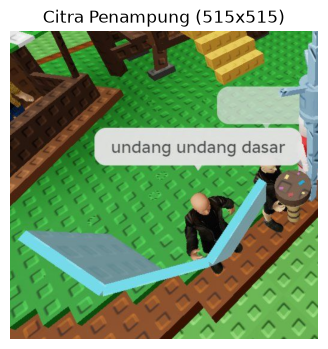

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

citra_penampung = None

def pilih_berkas_citra():
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        jalur = filedialog.askopenfilename(
            title="Pilih Berkas Citra Penampung",
            filetypes=[("Berkas Citra", "*.png *.jpg *.jpeg *.bmp")]
        )
        root.destroy()
        return jalur
    except Exception:
        return ""

jalur_citra = pilih_berkas_citra()

if not jalur_citra or not os.path.exists(jalur_citra):
    jalur_citra = input("Masukkan jalur berkas citra (contoh: cover.png): ").strip().strip('"').strip("'")

if not os.path.exists(jalur_citra):
    raise FileNotFoundError(f"Berkas citra tidak ditemukan pada jalur: '{jalur_citra}'.")

citra_penampung = Image.open(jalur_citra).convert("RGB")
lebar, tinggi = citra_penampung.size
kapasitas_byte = (lebar * tinggi * 3 - 32) // 8 - 28

print(f"[STATUS] Berkas citra berhasil dimuat: '{os.path.basename(jalur_citra)}'")
print(f"[STATUS] Resolusi Citra : {lebar} x {tinggi} piksel")
print(f"[STATUS] Kapasitas Maksimum Payload : {kapasitas_byte:,} byte ({kapasitas_byte / 1024:.2f} KB)")

plt.figure(figsize=(4, 4))
plt.imshow(citra_penampung)
plt.title(f"Citra Penampung ({lebar}x{tinggi})")
plt.axis("off")
plt.show()

## Sel 2: Implementasi Modul Kriptografi AES-256 GCM dan Steganografi LSB

In [6]:
class KriptografiAES256:
    """
    Kelas enkripsi dan dekripsi menggunakan algoritma AES-256 GCM (Galois/Counter Mode).
    Format keluaran terenkripsi: Nonce (12 byte) + Ciphertext + Authentication Tag (16 byte).
    """
    def __init__(self, kunci=None):
        if kunci is None:
            self.kunci = AESGCM.generate_key(bit_length=256)
        else:
            self.kunci = kunci
        self.aesgcm = AESGCM(self.kunci)

    def enkripsi(self, data_plaintext: bytes) -> bytes:
        nonce = os.urandom(12)
        ciphertext = self.aesgcm.encrypt(nonce, data_plaintext, None)
        return nonce + ciphertext

    def dekripsi(self, paket_terenkripsi: bytes) -> bytes:
        if len(paket_terenkripsi) < 28:
            raise ValueError("Ukuran paket terenkripsi tidak memenuhi spesifikasi minimum (28 byte).")
        nonce = paket_terenkripsi[:12]
        ciphertext = paket_terenkripsi[12:]
        return self.aesgcm.decrypt(nonce, ciphertext, None)


class SteganografiLSB:
    """
    Kelas steganografi berbasis Least Significant Bit (LSB) pada format citra tanpa kompresi kehilangan data (Lossless PNG).
    Format data sisipan: Header Panjang Data (4 byte / 32 bit) + Data Biner Payload.
    """
    @staticmethod
    def sisipkan(citra: Image.Image, data_biner: bytes) -> Image.Image:
        panjang_data = len(data_biner)
        header = panjang_data.to_bytes(4, byteorder="big")
        paket_lengkap = header + data_biner

        # Konversi paket byte menjadi deretan bit (0 dan 1)
        bit_sisipan = np.unpackbits(np.frombuffer(paket_lengkap, dtype=np.uint8))

        matriks_piksel = np.array(citra, dtype=np.uint8)
        piksel_datar = matriks_piksel.reshape(-1)

        if len(bit_sisipan) > piksel_datar.size:
            raise ValueError(
                f"Ukuran bit sisipan ({len(bit_sisipan)} bit) melebihi kapasitas piksel citra ({piksel_datar.size} bit)."
            )

        # Modifikasi bit LSB menggunakan operasi bitwise AND dan OR
        piksel_datar[:len(bit_sisipan)] = (piksel_datar[:len(bit_sisipan)] & 254) | bit_sisipan

        return Image.fromarray(matriks_piksel)

    @staticmethod
    def ekstrak(citra_stego: Image.Image) -> bytes:
        matriks_piksel = np.array(citra_stego, dtype=np.uint8)
        piksel_datar = matriks_piksel.reshape(-1)

        # Ekstraksi 32 bit pertama untuk membaca panjang data payload
        bit_header = piksel_datar[:32] & 1
        byte_header = np.packbits(bit_header).tobytes()
        panjang_data = int.from_bytes(byte_header, byteorder="big")

        total_bit = 32 + (panjang_data * 8)
        if total_bit > piksel_datar.size:
            raise ValueError("Format data rusak atau ukuran payload melebihi batas piksel citra.")

        # Ekstraksi seluruh bit data payload
        bit_data = piksel_datar[32:total_bit] & 1
        return np.packbits(bit_data).tobytes()

print("[INFO] Modul KriptografiAES256 dan SteganografiLSB siap digunakan.")

[INFO] Modul KriptografiAES256 dan SteganografiLSB siap digunakan.


## Sel 3: Pengaturan Interaktif Payload 1

In [8]:
batas_maksimum = 15

print("Pengaturan Payload 1")
print(f"- Batas maksimum panjang teks: {batas_maksimum} karakter.")
print("- Tekan langsung [ENTER] untuk menghasilkan PIN 10 byte secara otomatis.\n")

masukan_pengguna = input("Masukkan teks rahasia: ").strip()

if not masukan_pengguna:
    angka_acak = np.random.randint(100000, 999999)
    payload_1_aktif = f"PIN#{angka_acak}"
    print(f"[STATUS] Dibuat otomatis: '{payload_1_aktif}' (Ukuran: {len(payload_1_aktif.encode('utf-8'))} byte)")
else:
    panjang_byte = len(masukan_pengguna.encode("utf-8"))
    if panjang_byte > batas_maksimum:
        raise ValueError(
            f"Ukuran teks ({panjang_byte} byte) melebihi batas yang ditentukan ({batas_maksimum} byte). "
            "Silakan jalankan ulang sel ini dan masukkan teks yang lebih ringkas."
        )
    payload_1_aktif = masukan_pengguna
    print(f"[STATUS] Masukan manual diterima: '{payload_1_aktif}' (Ukuran: {panjang_byte} byte)")

Pengaturan Payload 1
- Batas maksimum panjang teks: 15 karakter.
- Tekan langsung [ENTER] untuk menghasilkan PIN 10 byte secara otomatis.

[STATUS] Masukan manual diterima: 'wowomati' (Ukuran: 8 byte)


## Sel 4: Pengujian Komprehensif 10 Payload

In [9]:
if citra_penampung is None:
    raise ValueError("Citra penampung belum dimuat. Silakan jalankan Sel 1 terlebih dahulu.")

# 10 Payload
def siapkan_daftar_payload():
    return [
        {
            "no": 1,
            "kategori": "PIN/Kata Sandi (Input User)",
            "data": payload_1_aktif
        },
        {
            "no": 2,
            "kategori": "Data Kependudukan",
            "data": "NIK: 3578012304950001 | NAMA: AHMAD FAUZI KURNIAWAN"
        },
        {
            "no": 3,
            "kategori": "Bukti Transaksi Keuangan Digital",
            "data": "TRX-ID: 20261025-884920 | PENGIRIM: 08123456789 | PENERIMA: 08987654321 | NOMINAL: RP 2.500.000 | STATUS: SUKSES"
        },
        {
            "no": 4,
            "kategori": "Komunikasi Obrolan Singkat",
            "data": (
                "Pemberitahuan Tim Operasional: Pelaksanaan deployment patch keamanan sistem perbankan "
                "akan dijadwalkan pada hari Sabtu pukul 23.00 WIB. Seluruh simpul basis data cadangan "
                "diwajibkan melakukan sinkronisasi penuh sebelum proses dimulai. Lakukan konfirmasi segera."
            )
        },
        {
            "no": 5,
            "kategori": "Catatan Rekam Medis Klinis",
            "data": (
                "REKAM MEDIS PASIEN - RS CIPTO MANGUNKUSUMO\n"
                "No RM: RM-994821 | Golongan Darah: O+ | Tekanan Darah: 120/80 mmHg\n"
                "Diagnosis Utama: Hipertensi Primer Derajat I dan Dislipidemia Ringan.\n"
                "Tindakan Lanjutan: Terapi farmakologi Amlodipine 5mg sekali sehari pagi hari, "
                "diet rendah garam natrium <2 gram/hari, serta anjuran olahraga aerobik 150 menit/minggu.\n"
                "Evaluasi profil lipid plasma darah dijadwalkan 30 hari ke depan pada poliklinik penyakit dalam."
            )
        },
        {
            "no": 6,
            "kategori": "Kredensial Server & Token Akses (1 KB)",
            "data": (
                "# KONFIGURASI KONEKSI DATABASE DAN KUNCI AKSES SERVER UTAMA\n"
                "DATABASE_HOST=db-cluster-node01.internal.corp\n"
                "DATABASE_PORT=5432\n"
                "DATABASE_USER=svc_production_runner\n"
                "DATABASE_PASSWORD=v9$Xq7!Lm2@Wz#91K_SecuredCredentials\n"
                "API_JWT_SECRET=eyJhbGciOiJIUzI1NiIsInR5cCI6IkpXVCJ9.sFlKxwRJSMeKKF2QT4fwpMeJf36POk6yJV_adQssw5c\n"
                + ("# DATA BLOK PENGAMAN SISTEM ENTERPRISE\n" * 18)
            )
        },
        {
            "no": 7,
            "kategori": "Dokumen Kerahasiaan/NDA (2.5 KB)",
            "data": (
                "PERJANJIAN KERAHASIAAN INFORMASI BERSAMA (NON-DISCLOSURE AGREEMENT)\n"
                "Pasal 1: Batasan Ruang Lingkup Rahasia Dagang dan Properti Intelektual.\n"
                "Seluruh data arsitektur jaringan, kode sumber, dan dokumentasi algoritma merupakan hak mutlak perusahaan.\n"
                + ("Klausul Perlindungan Data: Pihak kedua wajib mematuhi seluruh protokol pengamanan data berstandar ISO 27001.\n" * 22)
            )
        },
        {
            "no": 8,
            "kategori": "Berkas Log Insiden Firewall (5 KB)",
            "data": (
                "TIMESTAMP [2026-10-25 14:00:00] SRC_IP: 192.168.1.105 DST_IP: 10.0.0.1 PROTO: TCP PORT: 443 ACTION: ALLOW\n"
                + ("TIMESTAMP [2026-10-25 14:00:01] SRC_IP: 203.0.113.42 DST_IP: 10.0.0.50 PROTO: TCP PORT: 22 ACTION: DROP_REJECT\n" * 50)
            )
        },
        {
            "no": 9,
            "kategori": "Direktori Data Karyawan & Gaji (10 KB)",
            "data": (
                "LAPORAN GAJI DIVISI TEKNOLOGI INFORMASI\n"
                + ("EMP-ID: 7701 | DIV: CYBERSECURITY | NAMA: STAF ANALIS | GAJI_POKOK: RP 18.500.000 | STATUS: TETAP\n" * 105)
            )
        },
        {
            "no": 10,
            "kategori": "Laporan Audit Forensik Sistem (20 KB)",
            "data": (
                "LAPORAN RESMI AUDIT FORENSIK DAN ANALISIS INTEGRITAS SISTEM INFORMASI TAHUNAN\n"
                + ("HASIL PEMERIKSAAN CHECKSUM SHA-256 PADA BERKAS BINER SISTEM: STATUS VALID TANPA ANOMALI.\n" * 200)
            )
        }
    ]

daftar_payload = siapkan_daftar_payload()
hasil_evaluasi = []
daftar_citra_stego = []
stego_terakhir = None

modul_kripto = KriptografiAES256()
matriks_asli = np.array(citra_penampung)

print("[PROSES] Memulai siklus pengujian 10 payload...")

for item in daftar_payload:
    no = item["no"]
    kategori = item["kategori"]
    teks_payload = item["data"]
    payload_bytes = teks_payload.encode("utf-8")
    ukuran_payload = len(payload_bytes)

    waktu_awal = time.perf_counter()

    # 1. Enkripsi data menggunakan AES-256 GCM
    paket_terenkripsi = modul_kripto.enkripsi(payload_bytes)
    ukuran_terenkripsi = len(paket_terenkripsi)

    # 2. Penyisipan LSB ke dalam citra
    citra_stego = SteganografiLSB.sisipkan(citra_penampung, paket_terenkripsi)
    daftar_citra_stego.append(citra_stego)
    stego_terakhir = citra_stego

    # 3. Ekstraksi paket biner dari citra stego
    paket_terekstrak = SteganografiLSB.ekstrak(citra_stego)

    # 4. Dekripsi paket menggunakan kunci AES-256
    payload_terpulih = modul_kripto.dekripsi(paket_terekstrak)

    waktu_total = time.perf_counter() - waktu_awal

    # Verifikasi integritas data
    status_pemulihan = (payload_terpulih == payload_bytes)

    # 5. Penghitungan metrik kualitas citra
    matriks_stego = np.array(citra_stego)
    nilai_mse = mean_squared_error(matriks_asli, matriks_stego)
    nilai_psnr = peak_signal_noise_ratio(matriks_asli, matriks_stego, data_range=255)
    nilai_ssim = structural_similarity(matriks_asli, matriks_stego, channel_axis=-1, data_range=255)

    hasil_evaluasi.append({
        "No": no,
        "Skenario Kasus": kategori,
        "Payload Asli (Byte)": ukuran_payload,
        "Data Terenkripsi (Byte)": ukuran_terenkripsi,
        "MSE": round(nilai_mse, 6),
        "PSNR (dB)": round(nilai_psnr, 2),
        "SSIM": round(nilai_ssim, 6),
        "Waktu Proses (Detik)": round(waktu_total, 5),
        "Integritas Data": "Sesuai" if status_pemulihan else "Gagal"
    })

    # 6. Menyimpan citra hasil steganografi (Wajib PNG lossless agar bit LSB tidak rusak)
    nama_file_stego = f"Gambar Stego {no}.png"
    citra_stego.save(nama_file_stego, format="PNG")

df_evaluasi = pd.DataFrame(hasil_evaluasi)
print("[SUKSES] Seluruh pengujian 10 payload berhasil diselesaikan.\n")
print("[INFO] 10 berkas citra stego berhasil disimpan: 'Gambar Stego 1.png' s.d. 'Gambar Stego 10.png'.\n")
df_evaluasi

[PROSES] Memulai siklus pengujian 10 payload...
[SUKSES] Seluruh pengujian 10 payload berhasil diselesaikan.

[INFO] 10 berkas citra stego berhasil disimpan: 'Gambar Stego 1.png' s.d. 'Gambar Stego 10.png'.



,No,Skenario Kasus,Payload Asli (Byte),Data Terenkripsi (Byte),MSE,PSNR (dB),SSIM,Waktu Proses (Detik),Integritas Data
0,1,PIN/Kata Sandi (Input User),8,36,0.000202,85.07,1.000000,0.00133,Sesuai
1,2,Data Kependudukan,51,79,0.000410,82.01,1.000000,0.00215,Sesuai
2,3,Bukti Transaksi Keuangan Digital,112,140,0.000734,79.47,1.000000,0.00144,Sesuai
3,4,Komunikasi Obrolan Singkat,261,289,0.001467,76.47,0.999999,0.00159,Sesuai
4,5,Catatan Rekam Medis Klinis,442,470,0.002373,74.38,0.999997,0.00156,Sesuai
5,6,Kredensial Server & Token Akses (1 KB),1014,1042,0.005333,70.86,0.999989,0.00171,Sesuai
6,7,Dokumen Kerahasiaan/NDA (2.5 KB),2644,2672,0.013348,66.88,0.999954,0.00134,Sesuai
7,8,Berkas Log Insiden Firewall (5 KB),5656,5684,0.028455,63.59,0.999884,0.00193,Sesuai
8,9,Direktori Data Karyawan & Gaji (10 KB),10330,10358,0.052050,60.97,0.999771,0.00265,Sesuai
9,10,Laporan Audit Forensik Sistem (20 KB),17878,17906,0.090169,58.58,0.999575,0.00166,Sesuai


## Sel 5: Visualisasi Grafik Analisis Kualitas Citra dan Kinerja Komputasi

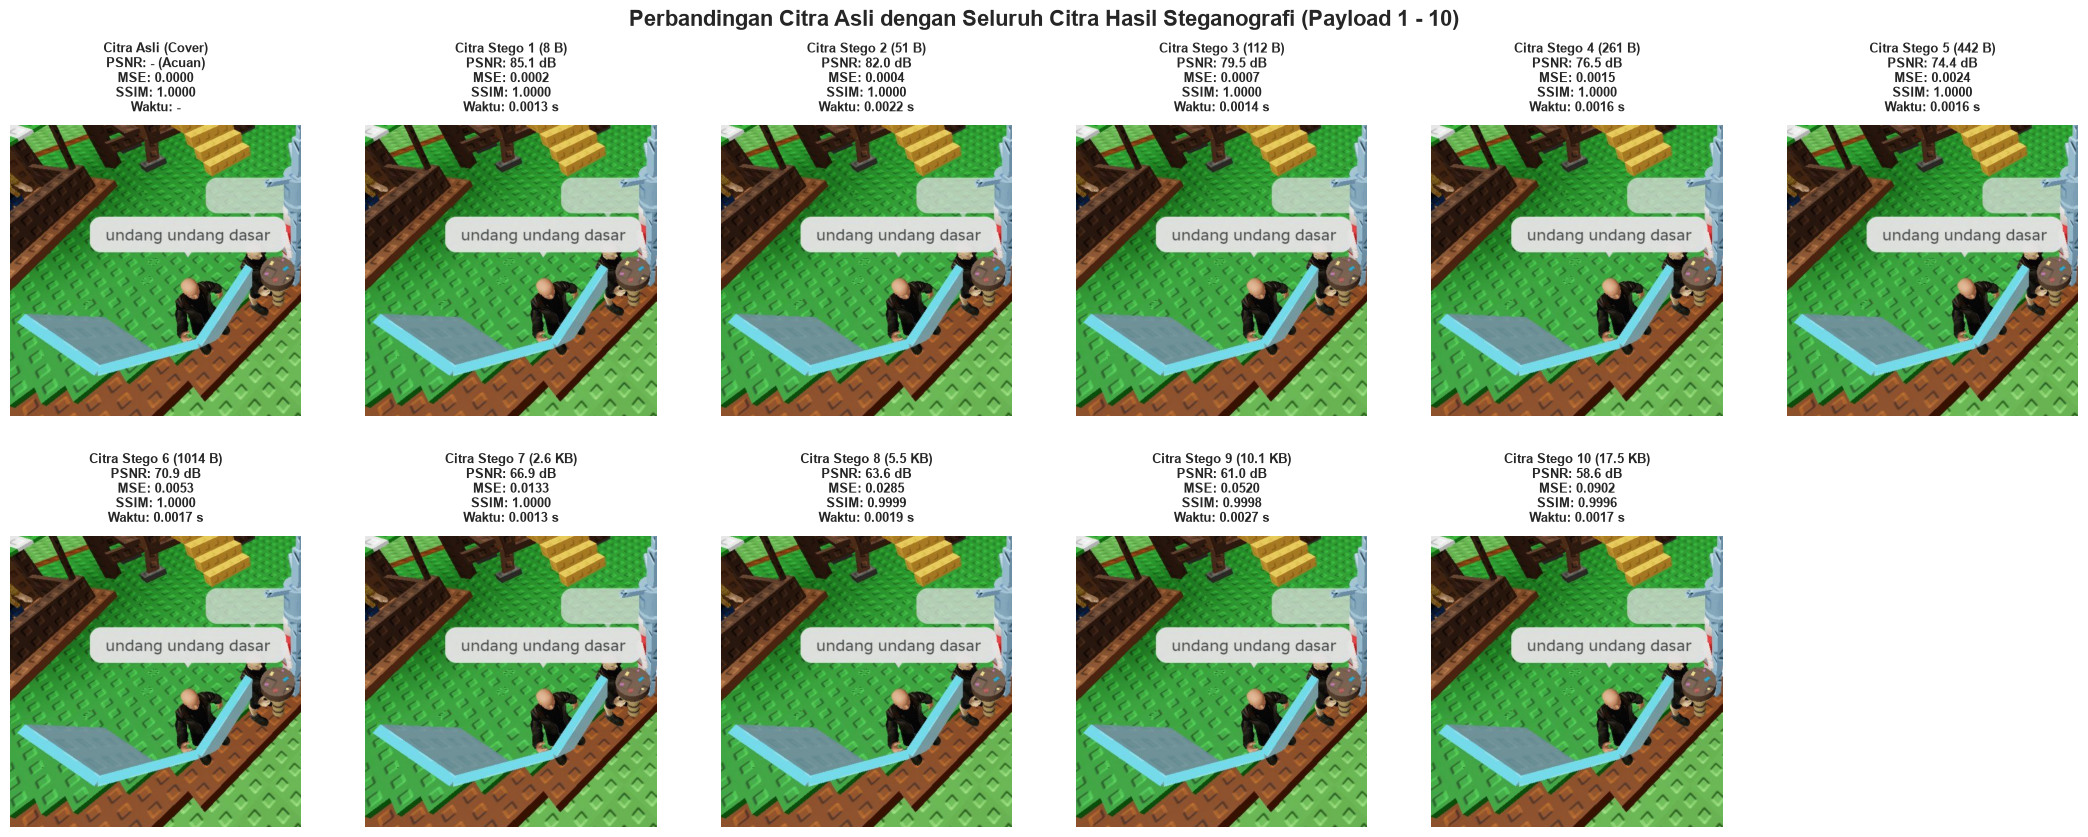

[INFO] Citra perbandingan lengkap berhasil disimpan ke berkas: 'perbandingan_citra_stego_lengkap.png' (Resolusi 300 DPI).



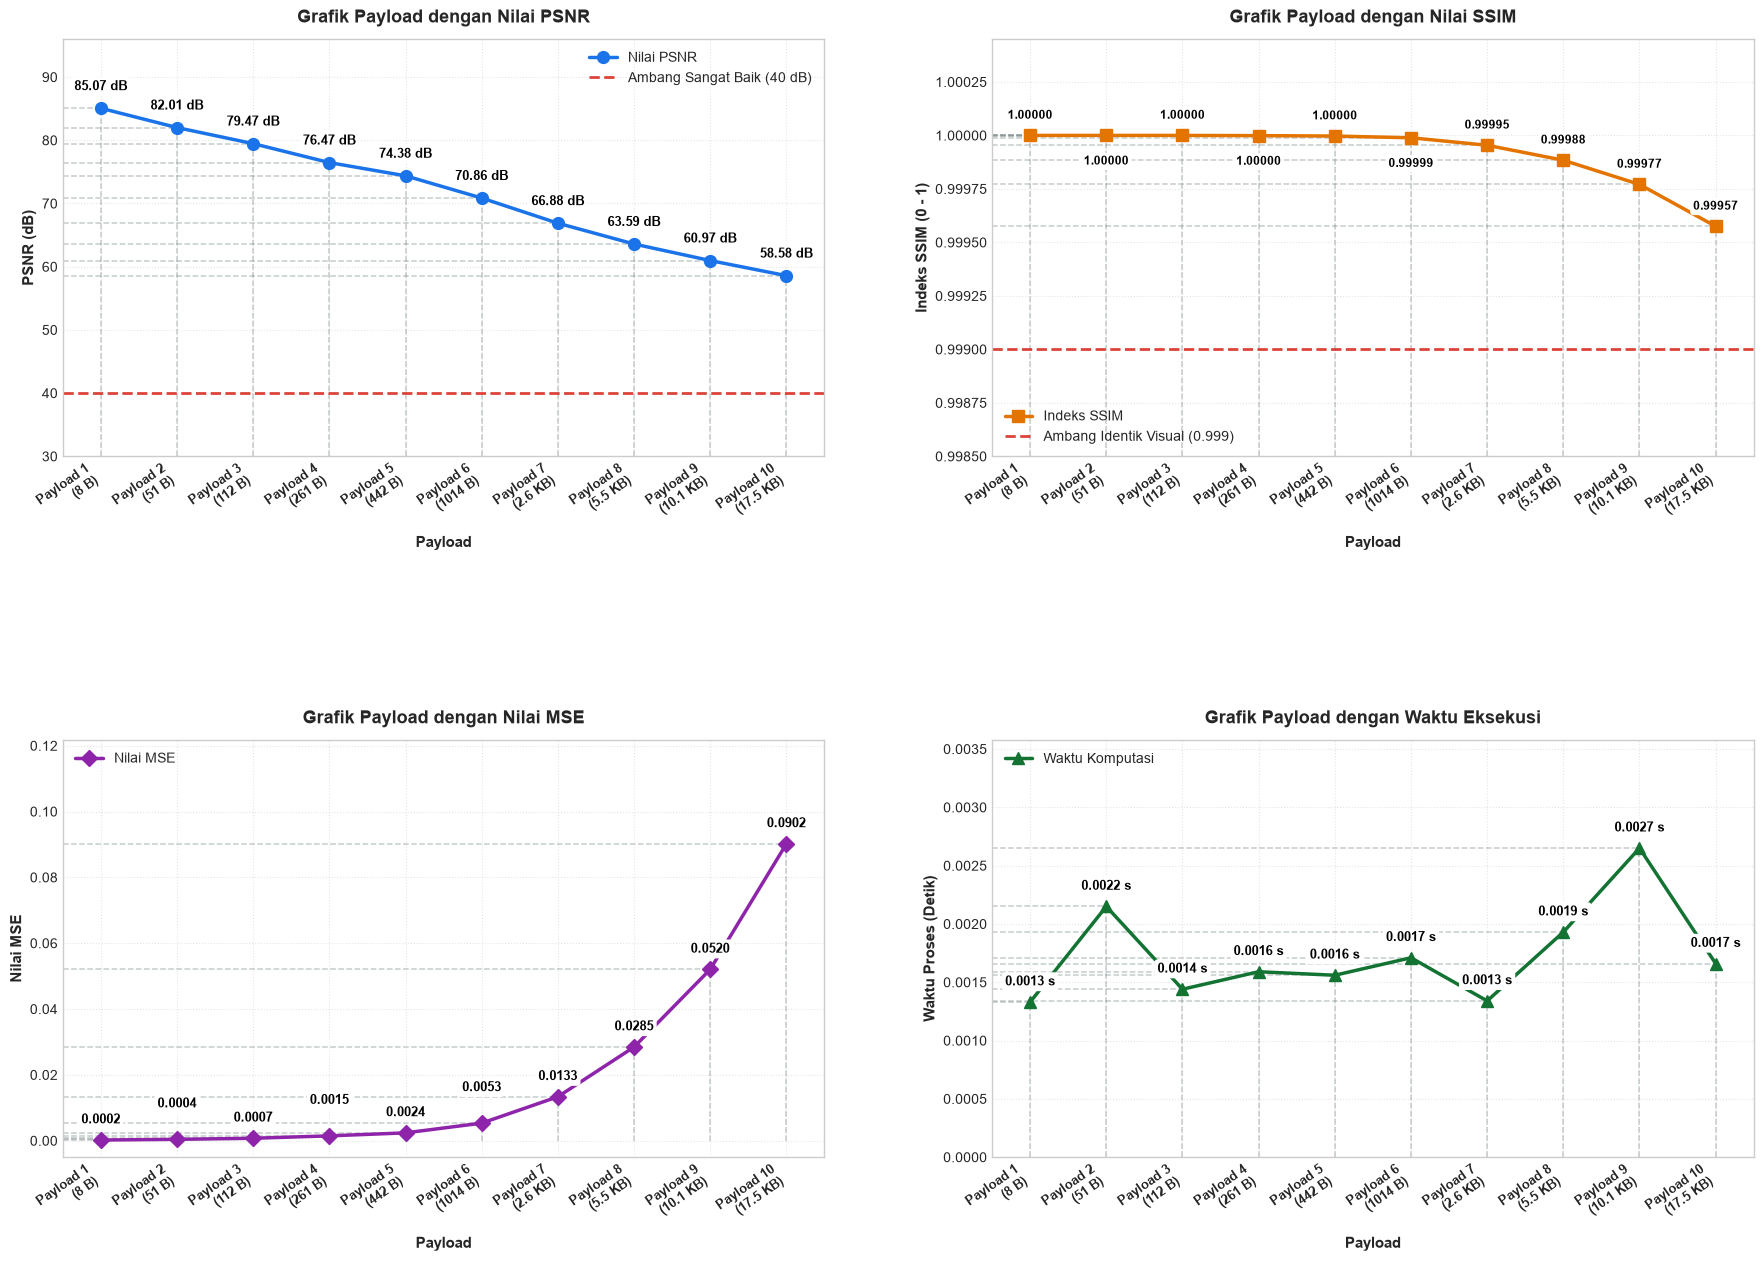

[INFO] Seluruh grafik evaluasi berhasil disimpan ke berkas: 'grafik_evaluasi_stego_kripto.png' (Resolusi 300 DPI).


In [10]:
# 1. Perbandingan Visual Citra Penampung Asli vs Seluruh Citra Stego (Payload 1 - 10)
fig_img, axes = plt.subplots(2, 6, figsize=(22, 8.8))
fig_img.subplots_adjust(
    hspace=0.32, wspace=0.22, top=0.86, bottom=0.04, left=0.03, right=0.97
)


def format_ukuran(b):
  return f"{b} B" if b < 1024 else f"{b/1024:.1f} KB"


# Slot [0, 0]: Citra Penampung Asli
img_cover_tampil = (
    citra_penampung
    if ("citra_penampung" in globals() and citra_penampung is not None)
    else None
)
if img_cover_tampil is None and os.path.exists("Gambar Stego 1.png"):
  img_cover_tampil = Image.open("Gambar Stego 1.png")

axes[0, 0].imshow(img_cover_tampil)
axes[0, 0].set_title(
    "Citra Asli (Cover)\n"
    "PSNR: - (Acuan)\n"
    "MSE: 0.0000\n"
    "SSIM: 1.0000\n"
    "Waktu: -",
    fontsize=9.2,
    fontweight="bold",
    pad=10,
)
axes[0, 0].axis("off")

# Baris 1: Stego 1 s.d. 5
for i in range(5):
  col = i + 1
  row_data = df_evaluasi.iloc[i]
  no = int(row_data["No"])

  stego_img = None
  daftar_stego = globals().get("daftar_citra_stego")
  if daftar_stego is not None and len(daftar_stego) >= no:
    stego_img = daftar_stego[no - 1]
  elif os.path.exists(f"Gambar Stego {no}.png"):
    stego_img = Image.open(f"Gambar Stego {no}.png")
  else:
    stego_img = img_cover_tampil

  axes[0, col].imshow(stego_img)
  axes[0, col].set_title(
      f"Citra Stego {no} ({format_ukuran(int(row_data['Payload Asli (Byte)']))})\n"
      f"PSNR: {row_data['PSNR (dB)']:.1f} dB\n"
      f"MSE: {row_data['MSE']:.4f}\n"
      f"SSIM: {row_data['SSIM']:.4f}\n"
      f"Waktu: {row_data['Waktu Proses (Detik)']:.4f} s",
      fontsize=9.2,
      fontweight="bold",
      pad=10,
  )
  axes[0, col].axis("off")

# Baris 2: Stego 6 s.d. 10
for i in range(5, 10):
  col = i - 5
  row_data = df_evaluasi.iloc[i]
  no = int(row_data["No"])

  stego_img = None
  daftar_stego = globals().get("daftar_citra_stego")
  if daftar_stego is not None and len(daftar_stego) >= no:
    stego_img = daftar_stego[no - 1]
  elif os.path.exists(f"Gambar Stego {no}.png"):
    stego_img = Image.open(f"Gambar Stego {no}.png")
  else:
    stego_img = img_cover_tampil

  axes[1, col].imshow(stego_img)
  axes[1, col].set_title(
      f"Citra Stego {no} ({format_ukuran(int(row_data['Payload Asli (Byte)']))})\n"
      f"PSNR: {row_data['PSNR (dB)']:.1f} dB\n"
      f"MSE: {row_data['MSE']:.4f}\n"
      f"SSIM: {row_data['SSIM']:.4f}\n"
      f"Waktu: {row_data['Waktu Proses (Detik)']:.4f} s",
      fontsize=9.2,
      fontweight="bold",
      pad=10,
  )
  axes[1, col].axis("off")

axes[1, 5].axis("off")
axes[1, 5].set_visible(False)

fig_img.suptitle(
    "Perbandingan Citra Asli dengan Seluruh Citra Hasil Steganografi (Payload 1"
    " - 10)",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)
nama_file_perbandingan = "perbandingan_citra_stego_lengkap.png"
plt.savefig(nama_file_perbandingan, dpi=300, bbox_inches="tight")
plt.show()


print(f"[INFO] Citra perbandingan lengkap berhasil disimpan ke berkas: '{nama_file_perbandingan}' (Resolusi 300 DPI).\n")

# 2. Grafik Evaluasi Kualitas Citra dan Kinerja Komputasi (Grid 2x2)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(19, 13))
fig.subplots_adjust(hspace=0.68, wspace=0.22, top=0.94, bottom=0.08, left=0.07, right=0.96)

x_indices = np.arange(len(df_evaluasi))
label_sumbu_x = [
    f"Payload {int(row['No'])}\n({format_ukuran(int(row['Payload Asli (Byte)']))})"
    for _, row in df_evaluasi.iterrows()
]

x_min_limit = -0.5
x_max_limit = 9.5

# --- Grafik 1: Nilai PSNR terhadap Payload ---
warna_psnr = "#1a73e8"
y_min_psnr = 30 
y_max_psnr = 96
ax1.plot(x_indices, df_evaluasi["PSNR (dB)"], marker="o", markersize=8.5, color=warna_psnr, linewidth=2.5, label="Nilai PSNR", zorder=3)
ax1.axhline(y=40, color="#d93025", linestyle="--", linewidth=2.0, alpha=0.9, label="Ambang Sangat Baik (40 dB)", zorder=2)

for x, y in zip(x_indices, df_evaluasi["PSNR (dB)"]):
    ax1.vlines(x=x, ymin=y_min_psnr, ymax=y, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)
    ax1.hlines(y=y, xmin=x_min_limit, xmax=x, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)

ax1.set_title("Grafik Payload dengan Nilai PSNR", fontsize=13, fontweight="bold", pad=12)
ax1.set_xlabel("Payload", fontsize=11, fontweight="bold", labelpad=8)
ax1.set_ylabel("PSNR (dB)", fontsize=11, fontweight="bold")
ax1.set_xlim(x_min_limit, x_max_limit)
ax1.set_ylim(y_min_psnr, y_max_psnr)
ax1.set_xticks(x_indices)
ax1.set_xticklabels(label_sumbu_x, rotation=35, ha="right", fontsize=9.5, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="upper right", framealpha=0.95, fontsize=10)

for x, y in zip(x_indices, df_evaluasi["PSNR (dB)"]):
    ax1.annotate(
        f"{y:.2f} dB",
        (x, y),
        textcoords="offset points",
        xytext=(0, 13),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="black",
        zorder=10,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=1.0)
    )

# --- Grafik 2: Nilai SSIM terhadap Payload ---
warna_ssim = "#e37400"
y_min_ssim = 0.9985
y_max_ssim = 1.00045
ax2.plot(x_indices, df_evaluasi["SSIM"], marker="s", markersize=8.5, color=warna_ssim, linewidth=2.5, label="Indeks SSIM", zorder=3)
ax2.axhline(y=0.999, color="#d93025", linestyle="--", linewidth=2.0, alpha=0.9, label="Ambang Identik Visual (0.999)", zorder=2)

for x, y in zip(x_indices, df_evaluasi["SSIM"]):
    ax2.vlines(x=x, ymin=y_min_ssim, ymax=y, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)
    ax2.hlines(y=y, xmin=x_min_limit, xmax=x, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)

ax2.set_title("Grafik Payload dengan Nilai SSIM", fontsize=13, fontweight="bold", pad=12)
ax2.set_xlabel("Payload", fontsize=11, fontweight="bold", labelpad=8)
ax2.set_ylabel("Indeks SSIM (0 - 1)", fontsize=11, fontweight="bold")
ax2.set_xlim(x_min_limit, x_max_limit)
ax2.set_ylim(y_min_ssim, y_max_ssim)
ax2.set_xticks(x_indices)
ax2.set_xticklabels(label_sumbu_x, rotation=35, ha="right", fontsize=9.5, fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.legend(loc="lower left", framealpha=0.95, fontsize=10)

for i, (x, y) in enumerate(zip(x_indices, df_evaluasi["SSIM"])):
    offset_y = 12 if (i % 2 == 0 or i >= 6) else -21
    ax2.annotate(
        f"{y:.5f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, offset_y),
        ha="center",
        fontsize=8.5,
        fontweight="bold",
        color="black",
        zorder=10,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=1.0)
    )

# --- Grafik 3: Nilai MSE terhadap Payload (Sebelum Waktu Eksekusi) ---
warna_mse = "#8e24aa"
y_min_mse = -0.005
y_max_mse = max(df_evaluasi["MSE"]) * 1.35
ax3.plot(x_indices, df_evaluasi["MSE"], marker="D", markersize=8.5, color=warna_mse, linewidth=2.5, label="Nilai MSE", zorder=3)

for x, y in zip(x_indices, df_evaluasi["MSE"]):
    ax3.vlines(x=x, ymin=0, ymax=y, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)
    ax3.hlines(y=y, xmin=x_min_limit, xmax=x, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)

ax3.set_title("Grafik Payload dengan Nilai MSE", fontsize=13, fontweight="bold", pad=12)
ax3.set_xlabel("Payload", fontsize=11, fontweight="bold", labelpad=8)
ax3.set_ylabel("Nilai MSE", fontsize=11, fontweight="bold")
ax3.set_xlim(x_min_limit, x_max_limit)
ax3.set_ylim(y_min_mse, y_max_mse)
ax3.set_xticks(x_indices)
ax3.set_xticklabels(label_sumbu_x, rotation=35, ha="right", fontsize=9.5, fontweight="bold")
ax3.grid(True, linestyle=":", alpha=0.5)
ax3.legend(loc="upper left", framealpha=0.95, fontsize=10)

for i, (x, y) in enumerate(zip(x_indices, df_evaluasi["MSE"])):
    offset_y = 12 if (i % 2 == 0 or i >= 6) else 23
    ax3.annotate(
        f"{y:.4f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, offset_y),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="black",
        zorder=10,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=1.0)
    )

# --- Grafik 4: Waktu Eksekusi terhadap Payload ---
warna_waktu = "#137333"
y_min_waktu = 0.0
y_max_waktu = max(df_evaluasi["Waktu Proses (Detik)"]) * 1.35
ax4.plot(x_indices, df_evaluasi["Waktu Proses (Detik)"], marker="^", markersize=8.5, color=warna_waktu, linewidth=2.5, label="Waktu Komputasi", zorder=3)

for x, y in zip(x_indices, df_evaluasi["Waktu Proses (Detik)"]):
    ax4.vlines(x=x, ymin=y_min_waktu, ymax=y, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)
    ax4.hlines(y=y, xmin=x_min_limit, xmax=x, color="#7f8c8d", linestyle="--", alpha=0.45, linewidth=1.1, zorder=1)

ax4.set_title("Grafik Payload dengan Waktu Eksekusi", fontsize=13, fontweight="bold", pad=12)
ax4.set_xlabel("Payload", fontsize=11, fontweight="bold", labelpad=8)
ax4.set_ylabel("Waktu Proses (Detik)", fontsize=11, fontweight="bold")
ax4.set_xlim(x_min_limit, x_max_limit)
ax4.set_ylim(y_min_waktu, y_max_waktu)
ax4.set_xticks(x_indices)
ax4.set_xticklabels(label_sumbu_x, rotation=35, ha="right", fontsize=9.5, fontweight="bold")
ax4.grid(True, linestyle=":", alpha=0.5)
ax4.legend(loc="upper left", framealpha=0.95, fontsize=10)

for x, y in zip(x_indices, df_evaluasi["Waktu Proses (Detik)"]):
    ax4.annotate(
        f"{y:.4f} s",
        (x, y),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9,
        fontweight="bold",
        color="black",
        zorder=10,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=1.0)
    )

nama_file_grafik = "grafik_evaluasi_stego_kripto.png"
plt.savefig(nama_file_grafik, dpi=300, bbox_inches="tight")
plt.show()

print(f"[INFO] Seluruh grafik evaluasi berhasil disimpan ke berkas: '{nama_file_grafik}' (Resolusi 300 DPI).")
